# Bankruptcy Prediction Pipeline
**Dataset:** Polish Companies Bankruptcy (UCI)
**Model:** XGBoost with Optuna hyperparameter tuning
**Goal:** Predict bankruptcy 2 years ahead (3year dataset)

## 1. Imports & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import os
import json
import warnings
warnings.filterwarnings('ignore')

from scipy.io import arff
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, fbeta_score,
    average_precision_score, matthews_corrcoef,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Set working directory
os.chdir(r'C:\Users\izanama\Documents\GitHub\bancrucy')
DEVICE = 'cuda'
print('Setup complete!')

c:\Users\izanama\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Setup complete!


## 2. Data Loading & Missing Value Imputation (MICE + Random Forest)

In [2]:
from sklearn.exceptions import ConvergenceWarning

YEARS = ['1year', '2year', '3year', '4year', '5year']
os.makedirs('data/processed', exist_ok=True)

for year in YEARS:
    data, meta = arff.loadarff(f'data/{year}.arff')
    df_year = pd.DataFrame(data)
    X_year = df_year.drop(columns=['class'])
    y_year = df_year['class'].str.decode('utf-8').astype(int)   # b'0' -> 0

    # 1. Split FIRST: nothing below is ever fitted on the test set
    X_train, X_test, y_train, y_test = train_test_split(
        X_year, y_year, test_size=0.2, stratify=y_year, random_state=42
    )

    # 2. Winsorization: bounds learned on train only, applied to both
    low  = X_train.quantile(0.01)          # Series: one value per column
    high = X_train.quantile(0.99)
    X_train = X_train.clip(lower=low, upper=high, axis=1)
    X_test  = X_test.clip(lower=low, upper=high, axis=1)

    # 3. MICE imputation: fit on train, only transform test
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        imputer = IterativeImputer(
            estimator=RandomForestRegressor(n_estimators=10, random_state=42, n_jobs=-1),
            max_iter=5, random_state=42, verbose=0
        )
        X_train = pd.DataFrame(imputer.fit_transform(X_train),
                               columns=X_train.columns, index=X_train.index)
        X_test  = pd.DataFrame(imputer.transform(X_test),
                               columns=X_test.columns, index=X_test.index)

    # 4. Save train and test separately
    train_df = X_train.copy(); train_df['class'] = y_train
    test_df  = X_test.copy();  test_df['class']  = y_test
    train_df.to_csv(f'data/processed/{year}_train.csv', index=False)
    test_df.to_csv(f'data/processed/{year}_test.csv', index=False)

    print(f'{year}: train {len(train_df)}, test {len(test_df)}, '
          f'NaN left: {train_df.isna().sum().sum() + test_df.isna().sum().sum()}')

1year: train 5621, test 1406, NaN left: 0
2year: train 8138, test 2035, NaN left: 0
3year: train 8402, test 2101, NaN left: 0
4year: train 7833, test 1959, NaN left: 0
5year: train 4728, test 1182, NaN left: 0


In [3]:
def load_split(year):
    train = pd.read_csv(f'data/processed/{year}_train.csv')
    test  = pd.read_csv(f'data/processed/{year}_test.csv')
    return (train.drop(columns='class'), test.drop(columns='class'),
            train['class'], test['class'])

## 3. Hyperparameter Tuning with Optuna (F2 Score)

In [ ]:
from sklearn.metrics import fbeta_score, make_scorer

f2_scorer = make_scorer(fbeta_score, beta=2)
best_params_per_year = {}

for year in ['1year', '2year', '3year', '4year', '5year']:
    print(f'Optimizing {year}...')

    X_train, X_test, y_train, y_test = load_split(year)
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    def objective(trial):
        params = {
            'n_estimators':      trial.suggest_int('n_estimators', 100, 1000),
            'max_depth':         trial.suggest_int('max_depth', 3, 10),
            'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'min_child_weight':  trial.suggest_int('min_child_weight', 1, 10),
            'gamma':             trial.suggest_float('gamma', 0, 5),
            'scale_pos_weight':  trial.suggest_float('scale_pos_weight', scale_pos_weight, scale_pos_weight * 3),
            'device':            'cuda',
            'random_state':      42,
        }
        model = XGBClassifier(**params)
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring=f2_scorer)
        return scores.mean()

    study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
    )
    study.optimize(objective, n_trials=50, show_progress_bar=True)
    best_params_per_year[year] = study.best_params
    print(f'{year} best F2: {study.best_value:.4f}\n')

# Save params to file
with open('best_params.json', 'w') as f:
    json.dump(best_params_per_year, f)
print('Best params saved to best_params.json!')

Optimizing 1year...


Best trial: 14. Best value: 0.377981: 100%|██████████| 50/50 [04:01<00:00,  4.83s/it]


1year best F2: 0.3780

Optimizing 2year...


Best trial: 29. Best value: 0.37292: 100%|██████████| 50/50 [03:24<00:00,  4.10s/it] 


2year best F2: 0.3729

Optimizing 3year...


...

3year best F2: 0.4202

Optimizing 4year...


Best trial: 22. Best value: 0.458542: 100%|██████████| 50/50 [04:42<00:00,  5.65s/it]


4year best F2: 0.4585

Optimizing 5year...


Best trial: 22. Best value: 0.571379: 100%|██████████| 50/50 [02:56<00:00,  3.53s/it]

5year best F2: 0.5714

Best params saved to best_params.json!


## 4. Load Saved Params (skip Optuna if already run)

In [5]:
with open('best_params.json', 'r') as f:
    best_params_per_year = json.load(f)
print('Params loaded!')
print(best_params_per_year['3year'])

Params loaded!
{'n_estimators': 996, 'max_depth': 6, 'learning_rate': 0.012031076543543054, 'subsample': 0.7064417846693288, 'colsample_bytree': 0.9678603486946612, 'min_child_weight': 7, 'gamma': 3.763391090692823, 'scale_pos_weight': 59.09393894442636}


## 5. Model Performance Across All Years

In [18]:
print(f"{'Year':<8} {'ROC-AUC':<10} {'PR-AUC':<10}")
print('=' * 28)

for year in YEARS:
    X_tr, X_te, y_tr, y_te = load_split(year)

    model = XGBClassifier(**best_params_per_year[year], device=DEVICE, random_state=42)
    model.fit(X_tr, y_tr)

    proba = model.predict_proba(X_te)[:, 1]
    print(f'{year:<8} {roc_auc_score(y_te, proba):<10.4f} '
          f'{average_precision_score(y_te, proba):<10.4f}')

Year     ROC-AUC    PR-AUC    
1year    0.8618     0.2748    
2year    0.8304     0.2997    
3year    0.8654     0.3903    
4year    0.8303     0.3586    
5year    0.9010     0.4855    


## 6. Final Model — 3year Dataset (3-year Prediction Horizon)

In [14]:
X_train, X_test, y_train, y_test = load_split('3year')
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# XGBoost
model_xgb = XGBClassifier(**best_params_per_year['3year'], device=DEVICE, random_state=42)
model_xgb.fit(X_train, y_train)
y_proba     = model_xgb.predict_proba(X_test)[:, 1]

# Random Forest (baseline)
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight={0: 1, 1: scale_pos_weight},
    random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print(f'XGBoost        ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}   '
      f'PR-AUC: {average_precision_score(y_test, y_proba):.4f}')
print(f'Random Forest  ROC-AUC: {roc_auc_score(y_test, y_proba_rf):.4f}   '
      f'PR-AUC: {average_precision_score(y_test, y_proba_rf):.4f}')

XGBoost        ROC-AUC: 0.8654   PR-AUC: 0.3903
Random Forest  ROC-AUC: 0.8283   PR-AUC: 0.2348


In [15]:
from sklearn.model_selection import cross_val_predict

# 1. OOF probabilities on train
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = cross_val_predict(
    XGBClassifier(**best_params_per_year['3year'], device=DEVICE, random_state=42),
    X_train, y_train, cv=cv, method='predict_proba'
)[:, 1]

# 2. highest threshold with OOF recall ≥ 90%».
thresholds = np.arange(0.01, 0.91, 0.01)
recall_oof = [recall_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds]
best_t = max(t for t, r in zip(thresholds, recall_oof) if r >= 0.90)
print(f'Best threshold (OOF): {best_t:.2f}, '
      f'OOF recall: {recall_oof[list(thresholds).index(best_t)]:.4f}')

# 3. Apply once to test
y_pred_final = (y_proba >= best_t).astype(int)
print(f'\n=== Test, threshold = {best_t:.2f} ===')
print(f'Recall:    {recall_score(y_test, y_pred_final):.4f}')
print(f'Precision: {precision_score(y_test, y_pred_final):.4f}')
print(f'F2:        {fbeta_score(y_test, y_pred_final, beta=2):.4f}')
print(f'Cleared:   {(y_pred_final==0).sum()} / {len(y_test)}')
print(f'Bankrupts found: {((y_pred_final==1) & (y_test==1)).sum()} / {y_test.sum()}')

Best threshold (OOF): 0.04, OOF recall: 0.9217

=== Test, threshold = 0.04 ===
Recall:    0.9394
Precision: 0.0851
F2:        0.3123
Cleared:   1008 / 2101
Bankrupts found: 93 / 99


## 7. Threshold Analysis

In [16]:
print(f"{'Threshold':<12} {'Precision':<12} {'Recall':<10} {'F2':<8} {'Flagged %':<10}")
print('=' * 54)
for t in np.arange(0.05, 0.95, 0.05):
    y_pred_t = (oof_proba >= t).astype(int)
    if y_pred_t.sum() == 0:
        break
    p  = precision_score(y_train, y_pred_t)
    r  = recall_score(y_train, y_pred_t)
    f2 = fbeta_score(y_train, y_pred_t, beta=2)
    flagged = y_pred_t.mean() * 100
    print(f'{t:<12.2f} {p:<12.4f} {r:<10.4f} {f2:<8.4f} {flagged:<10.1f}')

print(f'\nChosen threshold: {best_t:.2f} (highest with OOF recall >= 90%)')

Threshold    Precision    Recall     F2       Flagged % 
0.05         0.0960       0.8990     0.3362   44.2      
0.10         0.1205       0.8131     0.3783   31.8      
0.15         0.1414       0.7475     0.4024   24.9      
0.20         0.1630       0.7045     0.4232   20.4      
0.25         0.1816       0.6439     0.4267   16.7      
0.30         0.2042       0.5934     0.4296   13.7      
0.35         0.2253       0.5631     0.4332   11.8      
0.40         0.2404       0.5227     0.4233   10.2      
0.45         0.2739       0.4924     0.4247   8.5       
0.50         0.3072       0.4646     0.4214   7.1       
0.55         0.3340       0.4116     0.3933   5.8       
0.60         0.3655       0.3636     0.3640   4.7       
0.65         0.3858       0.3157     0.3276   3.9       
0.70         0.4357       0.2652     0.2877   2.9       
0.75         0.4773       0.2121     0.2386   2.1       
0.80         0.5512       0.1768     0.2046   1.5       
0.85         0.5909       0.131

## 8. Visualizations

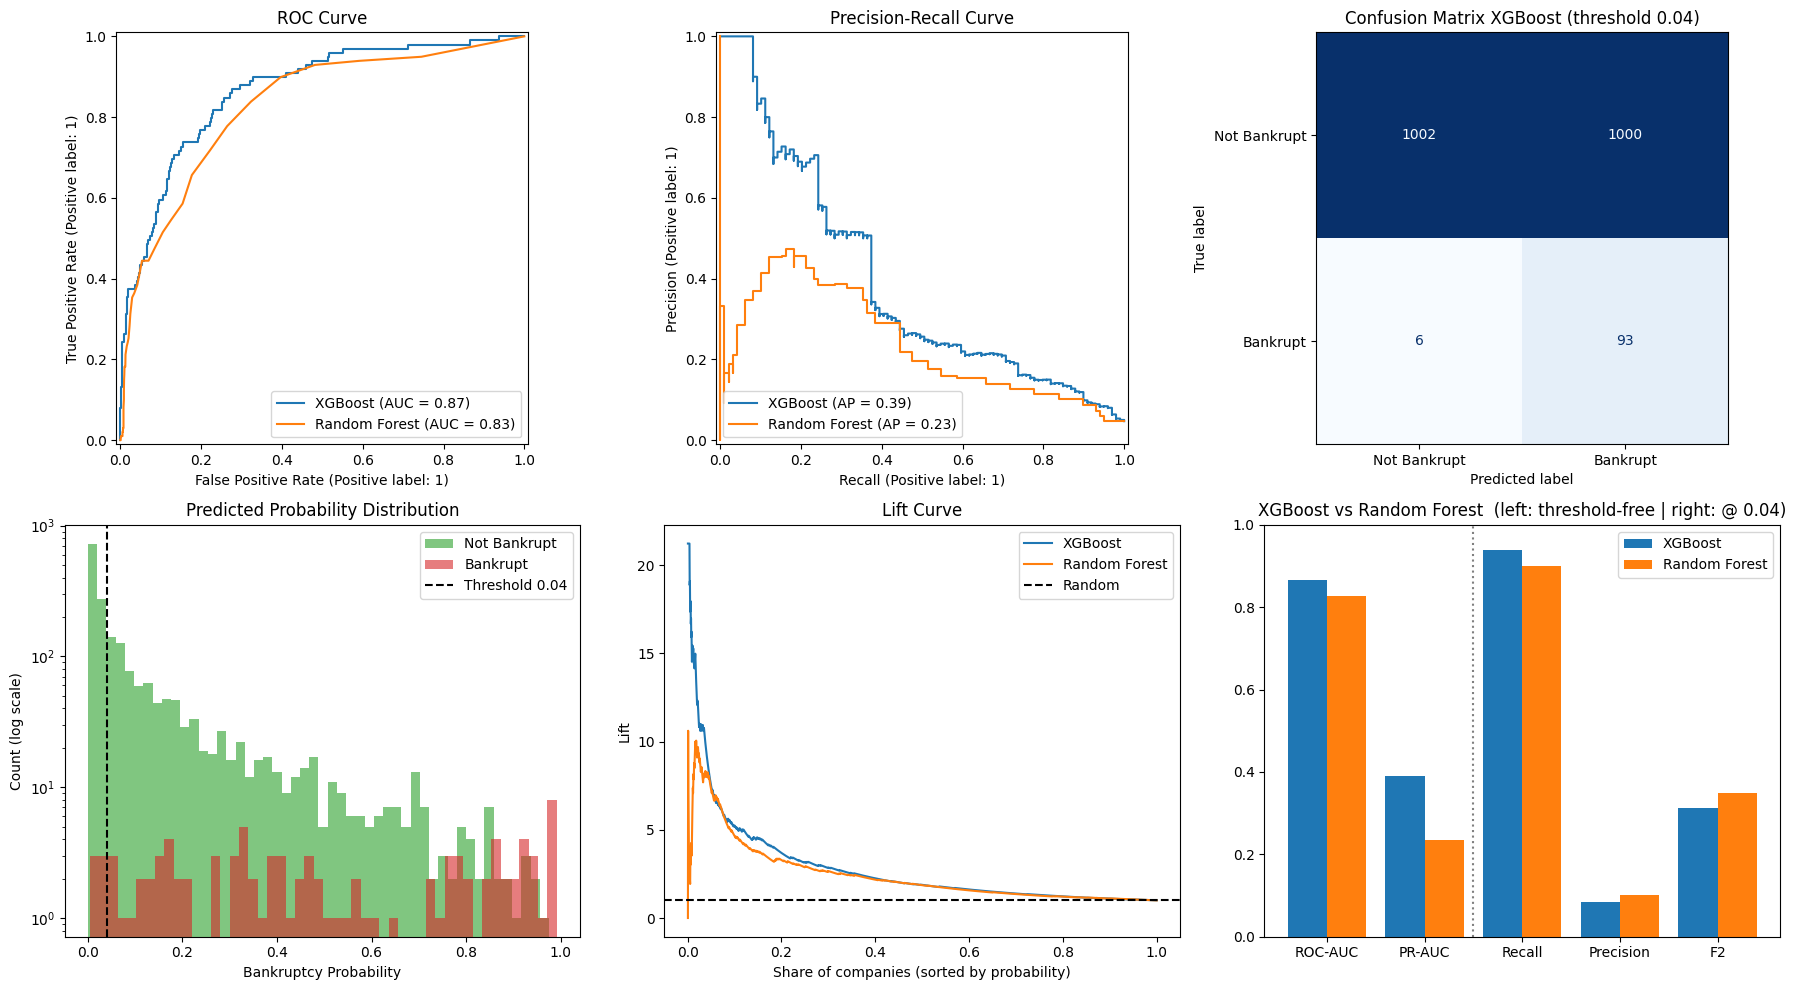

In [17]:
# Predictions at the chosen threshold
y_pred_final = (y_proba    >= best_t).astype(int)
y_pred_rf    = (y_proba_rf >= best_t).astype(int)

def compute_lift(y_true, y_proba):
    df_lift = pd.DataFrame({'true': y_true.values, 'proba': y_proba})
    df_lift = df_lift.sort_values('proba', ascending=False).reset_index(drop=True)
    df_lift['cumulative_pos'] = df_lift['true'].cumsum()
    df_lift['cumulative_pct'] = (df_lift.index + 1) / len(df_lift)
    df_lift['lift'] = (df_lift['cumulative_pos'] / (df_lift.index + 1)) / df_lift['true'].mean()
    return df_lift['cumulative_pct'], df_lift['lift']

C_XGB, C_RF = 'C0', 'C1'   # same colors on every panel
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. ROC Curve
RocCurveDisplay.from_predictions(y_test, y_proba,    ax=axes[0,0], name='XGBoost')
RocCurveDisplay.from_predictions(y_test, y_proba_rf, ax=axes[0,0], name='Random Forest')
axes[0,0].set_title('ROC Curve')

# 2. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_proba,    ax=axes[0,1], name='XGBoost')
PrecisionRecallDisplay.from_predictions(y_test, y_proba_rf, ax=axes[0,1], name='Random Forest')
axes[0,1].set_title('Precision-Recall Curve')

# 3. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_final,
    display_labels=['Not Bankrupt', 'Bankrupt'],
    cmap='Blues', colorbar=False, ax=axes[0,2]
)
axes[0,2].set_title(f'Confusion Matrix XGBoost (threshold {best_t:.2f})')

# 4. Probability Distribution
axes[1,0].hist(y_proba[y_test==0], bins=50, alpha=0.6, label='Not Bankrupt', color='tab:green')
axes[1,0].hist(y_proba[y_test==1], bins=50, alpha=0.6, label='Bankrupt',     color='tab:red')
axes[1,0].axvline(x=best_t, color='black', linestyle='--', label=f'Threshold {best_t:.2f}')
axes[1,0].set_yscale('log')   # bankrupt bars are otherwise invisible
axes[1,0].set_title('Predicted Probability Distribution')
axes[1,0].set_xlabel('Bankruptcy Probability')
axes[1,0].set_ylabel('Count (log scale)')
axes[1,0].legend()

# 5. Lift Curve
pct_xgb, lift_xgb = compute_lift(y_test, y_proba)
pct_rf,  lift_rf  = compute_lift(y_test, y_proba_rf)
axes[1,1].plot(pct_xgb, lift_xgb, label='XGBoost',       color=C_XGB)
axes[1,1].plot(pct_rf,  lift_rf,  label='Random Forest', color=C_RF)
axes[1,1].axhline(y=1, color='black', linestyle='--', label='Random')
axes[1,1].set_title('Lift Curve')
axes[1,1].set_xlabel('Share of companies (sorted by probability)')
axes[1,1].set_ylabel('Lift')
axes[1,1].legend()

# 6. Metrics Comparison (threshold-free | at chosen threshold)
metrics = {
    'ROC-AUC':   [roc_auc_score(y_test, y_proba),           roc_auc_score(y_test, y_proba_rf)],
    'PR-AUC':    [average_precision_score(y_test, y_proba), average_precision_score(y_test, y_proba_rf)],
    'Recall':    [recall_score(y_test, y_pred_final),       recall_score(y_test, y_pred_rf)],
    'Precision': [precision_score(y_test, y_pred_final),    precision_score(y_test, y_pred_rf)],
    'F2':        [fbeta_score(y_test, y_pred_final, beta=2), fbeta_score(y_test, y_pred_rf, beta=2)],
}
x = np.arange(len(metrics))
axes[1,2].bar(x - 0.2, [v[0] for v in metrics.values()], 0.4, label='XGBoost',       color=C_XGB)
axes[1,2].bar(x + 0.2, [v[1] for v in metrics.values()], 0.4, label='Random Forest', color=C_RF)
axes[1,2].axvline(x=1.5, color='grey', linestyle=':')   # separates threshold-free vs threshold metrics
axes[1,2].set_xticks(x)
axes[1,2].set_xticklabels(metrics.keys())
axes[1,2].set_ylim(0, 1)
axes[1,2].set_title(f'XGBoost vs Random Forest  (left: threshold-free | right: @ {best_t:.2f})')
axes[1,2].legend()

plt.tight_layout()
os.makedirs('images', exist_ok=True)
plt.savefig('images/model_results.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. SHAP Feature Importance

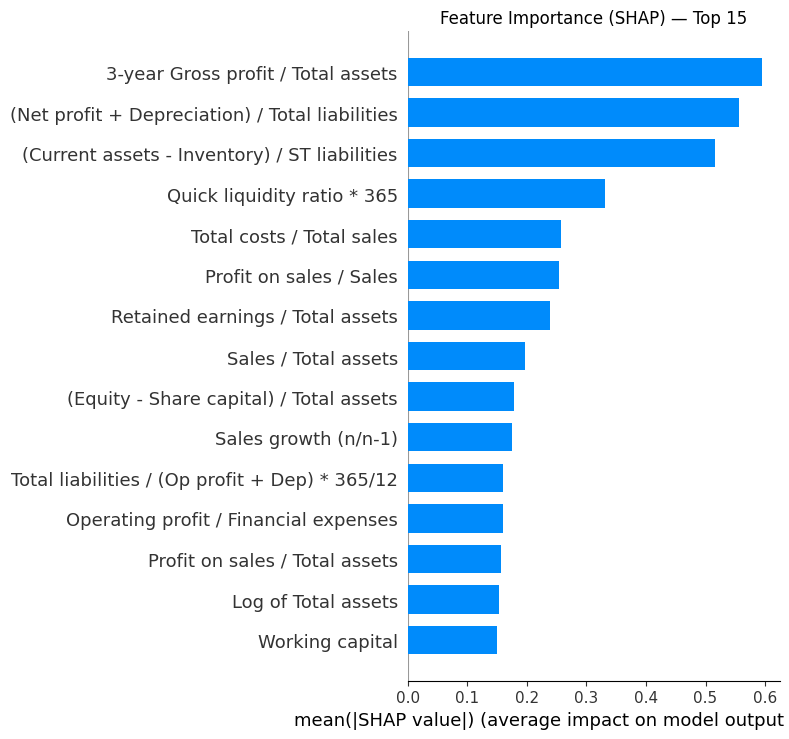

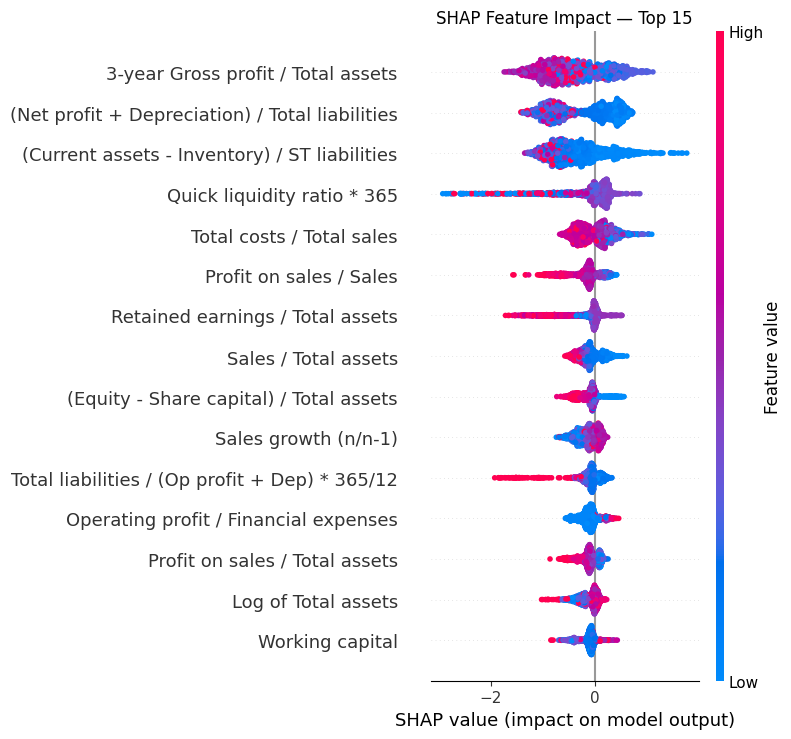

In [11]:
feature_names = {
    'Attr1': 'Net profit / Total assets',
    'Attr2': 'Total liabilities / Total assets',
    'Attr3': 'Working capital / Total assets',
    'Attr4': 'Current assets / ST liabilities',
    'Attr5': 'Quick liquidity ratio * 365',
    'Attr6': 'Retained earnings / Total assets',
    'Attr7': 'EBIT / Total assets',
    'Attr8': 'Book value of equity / Total liabilities',
    'Attr9': 'Sales / Total assets',
    'Attr10': 'Equity / Total assets',
    'Attr11': '(GP + Extraordinary + Fin exp) / Total assets',
    'Attr12': 'Gross profit / ST liabilities',
    'Attr13': '(Gross profit + Depreciation) / Sales',
    'Attr14': '(Gross profit + Interest) / Total assets',
    'Attr15': '(Total liabilities * 365) / (GP + Dep)',
    'Attr16': '(Gross profit + Depreciation) / Total liabilities',
    'Attr17': 'Total assets / Total liabilities',
    'Attr18': 'Gross profit / Total assets',
    'Attr19': 'Gross profit / Sales',
    'Attr20': '(Inventory * 365) / Sales',
    'Attr21': 'Sales growth (n/n-1)',
    'Attr22': 'Operating profit / Total assets',
    'Attr23': 'Net profit / Sales',
    'Attr24': '3-year Gross profit / Total assets',
    'Attr25': '(Equity - Share capital) / Total assets',
    'Attr26': '(Net profit + Depreciation) / Total liabilities',
    'Attr27': 'Operating profit / Financial expenses',
    'Attr28': 'Working capital / Fixed assets',
    'Attr29': 'Log of Total assets',
    'Attr30': '(Total liabilities - Cash) / Sales',
    'Attr31': '(Gross profit + Interest) / Sales',
    'Attr32': '(Current liabilities * 365) / COGS',
    'Attr33': 'Operating expenses / ST liabilities',
    'Attr34': 'Operating expenses / Total liabilities',
    'Attr35': 'Profit on sales / Total assets',
    'Attr36': 'Total sales / Total assets',
    'Attr37': '(Current assets - Inventories) / LT liabilities',
    'Attr38': 'Constant capital / Total assets',
    'Attr39': 'Profit on sales / Sales',
    'Attr40': '(Current assets - Inv - Rec) / ST liabilities',
    'Attr41': 'Total liabilities / (Op profit + Dep) * 365/12',
    'Attr42': 'Operating profit / Sales',
    'Attr43': 'Receivables + Inventory turnover days',
    'Attr44': '(Receivables * 365) / Sales',
    'Attr45': 'Net profit / Inventory',
    'Attr46': '(Current assets - Inventory) / ST liabilities',
    'Attr47': '(Inventory * 365) / COGS',
    'Attr48': 'EBITDA / Total assets',
    'Attr49': 'EBITDA / Sales',
    'Attr50': 'Current assets / Total liabilities',
    'Attr51': 'ST liabilities / Total assets',
    'Attr52': '(ST liabilities * 365) / COGS',
    'Attr53': 'Equity / Fixed assets',
    'Attr54': 'Constant capital / Fixed assets',
    'Attr55': 'Working capital',
    'Attr56': '(Sales - COGS) / Sales',
    'Attr57': '(CA - Inv - ST liab) / (Sales - GP - Dep)',
    'Attr58': 'Total costs / Total sales',
    'Attr59': 'LT liabilities / Equity',
    'Attr60': 'Sales / Inventory',
    'Attr61': 'Sales / Receivables',
    'Attr62': '(ST liabilities * 365) / Sales',
    'Attr63': 'Sales / ST liabilities',
    'Attr64': 'Sales / Fixed assets'
}

X_test_named = X_test.rename(columns=feature_names)
explainer    = shap.TreeExplainer(model_xgb)
shap_values  = explainer.shap_values(X_test_named)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_named, plot_type='bar', max_display=15, show=False)
plt.title('Feature Importance (SHAP) — Top 15')
plt.tight_layout()
plt.savefig('images/shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_named, max_display=15, show=False)
plt.title('SHAP Feature Impact — Top 15')
plt.tight_layout()
plt.savefig('images/shap_impact.png', dpi=150, bbox_inches='tight')
plt.show()